# Age & Gender Prediction — Improved Model
**Dataset:** UTKFace | **Base Model:** ResNet50 (ImageNet pretrained)

### Improvements over baseline:
1. `tf.data` pipeline — images loaded batch-by-batch, no RAM crash
2. `preprocess_input` — correct ResNet50 normalization
3. Age normalized to [0,1] — easier regression target
4. Bug fix: age head uses shared layer output (was using raw backbone output)
5. BatchNormalization + L2 regularization in prediction heads
6. Two-stage training: warm-up (frozen) then fine-tune last 60 layers
7. Gradient clipping + ModelCheckpoint

In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
import kagglehub
jangedoo_utkface_new_path = kagglehub.dataset_download('jangedoo/utkface-new')
print('Data source import complete.')

Data source import complete.


In [ ]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint
from tensorflow.keras.regularizers import l2
from PIL import Image as PILImage

print('TensorFlow version:', tf.__version__)
print('GPU available:', len(tf.config.list_physical_devices('GPU')) > 0)

2026-04-19 15:02:07.785464: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1776610927.961529      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1776610928.013611      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1776610928.378412      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776610928.378447      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776610928.378450      55 computation_placer.cc:177] computation placer alr

TensorFlow version: 2.19.0
GPU available: True


## 1. Find Dataset Path

In [ ]:
possible_paths = [
    '/kaggle/input/utkface-new/UTKFace',
    '/kaggle/input/utkface-new/utkface_aligned_cropped/UTKFace',
    '/kaggle/input/utkface-new',
    '/kaggle/input/utk-face/UTKFace',
    '/kaggle/input/utk-face',
]

dataset_path = None
for path in possible_paths:
    if os.path.exists(path) and any(f.endswith('.jpg') for f in os.listdir(path)):
        dataset_path = path
        break

if dataset_path is None:
    for root, dirs, files in os.walk('/kaggle/input'):
        if any(f.endswith('.jpg') for f in files):
            dataset_path = root
            break

if dataset_path is None:
    raise FileNotFoundError('Could not find UTKFace images. Check your dataset is added correctly.')

print(f'Dataset found at: {dataset_path}')
print(f'Sample files: {os.listdir(dataset_path)[:3]}')

Dataset found at: /kaggle/input/datasets/jangedoo/utkface-new/UTKFace
Sample files: ['26_0_2_20170104023102422.jpg.chip.jpg', '22_1_1_20170112233644761.jpg.chip.jpg', '21_1_3_20170105003215901.jpg.chip.jpg']


## 2. Load Metadata (file paths + labels only — no images loaded into RAM)

In [ ]:
image_paths, age_labels, gender_labels = [], [], []

for filename in os.listdir(dataset_path):
    if not filename.endswith('.jpg'):
        continue
    parts = filename.split('_')
    if len(parts) < 2:
        continue
    try:
        age    = int(parts[0])
        gender = int(parts[1])
        image_paths.append(os.path.join(dataset_path, filename))
        age_labels.append(age)
        gender_labels.append(gender)
    except ValueError:
        continue

df = pd.DataFrame({'image': image_paths, 'age': age_labels, 'gender': gender_labels})
print(f'Total samples: {len(df)}')
df.head()

Total samples: 23708


,image,age,gender
0,/kaggle/input/datasets/jangedoo/utkface-new/UT...,26,0
1,/kaggle/input/datasets/jangedoo/utkface-new/UT...,22,1
2,/kaggle/input/datasets/jangedoo/utkface-new/UT...,21,1
3,/kaggle/input/datasets/jangedoo/utkface-new/UT...,28,0
4,/kaggle/input/datasets/jangedoo/utkface-new/UT...,17,1


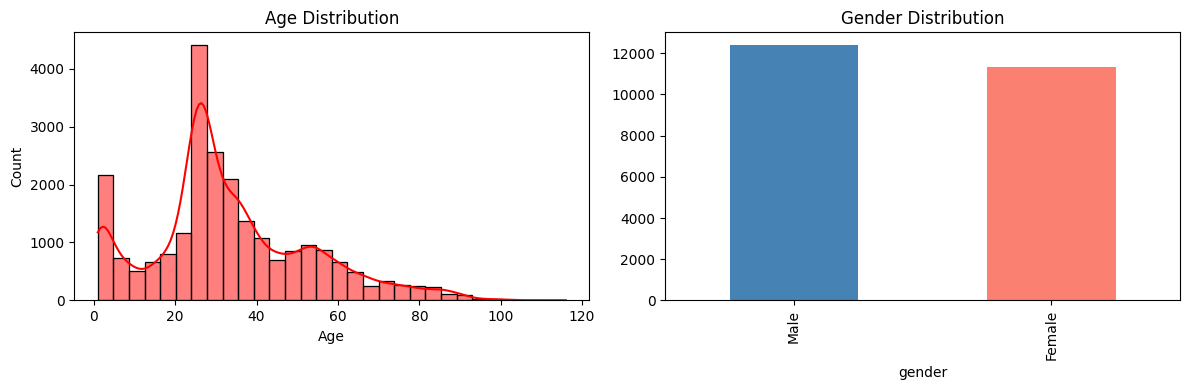

Age range: 1 to 116
Gender counts: {0: 12391, 1: 11317}


In [ ]:
gender_dict = {0: 'Male', 1: 'Female'}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['age'], color='red', bins=30, kde=True, ax=axes[0])
axes[0].set_title('Age Distribution')
axes[0].set_xlabel('Age')
df['gender'].map(gender_dict).value_counts().plot(kind='bar', color=['steelblue', 'salmon'], ax=axes[1])
axes[1].set_title('Gender Distribution')
plt.tight_layout()
plt.show()

print(f"Age range: {df['age'].min()} to {df['age'].max()}")
print(f"Gender counts: {df['gender'].value_counts().to_dict()}")

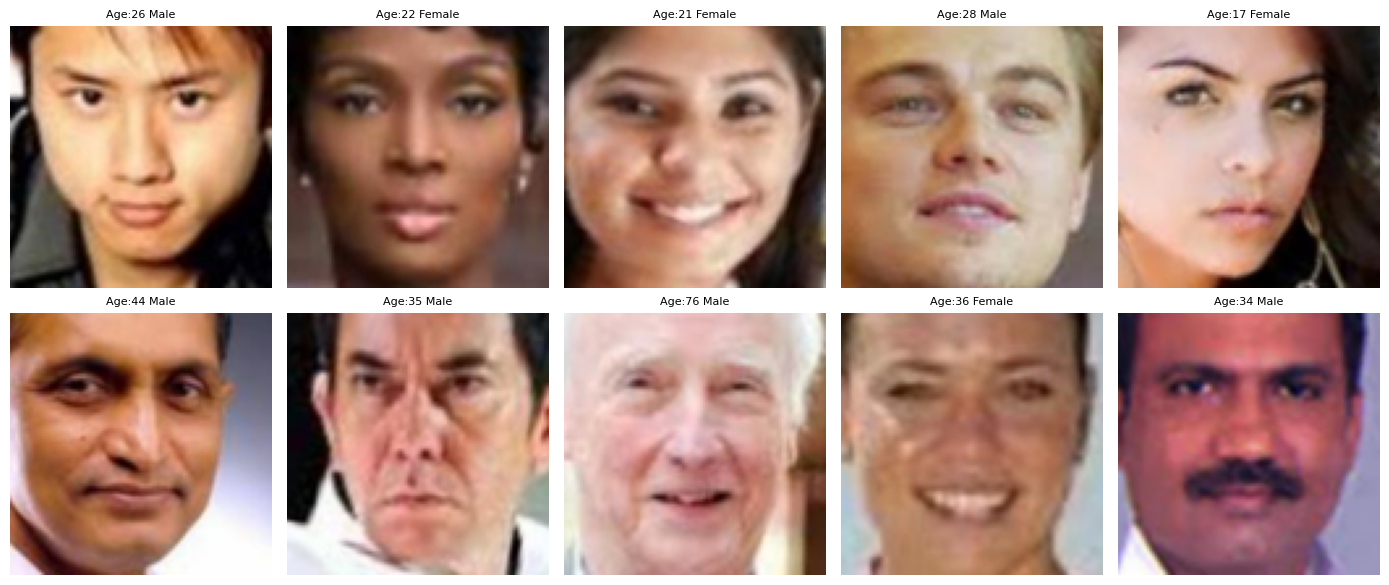

In [ ]:
# Show sample images — loaded one at a time using PIL, no large array
plt.figure(figsize=(14, 6))
for i in range(10):
    row = df.iloc[i]
    img = PILImage.open(row['image']).resize((100, 100))
    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(f"Age:{row['age']} {gender_dict[row['gender']]}", fontsize=8)
    plt.axis('off')
plt.tight_layout()
plt.show()

## 3. Build tf.data Pipeline
Images are read from disk one batch at a time during training.
Only 32 images are ever in RAM simultaneously — prevents the kernel crash.

In [ ]:
AGE_MAX  = 116.0
IMG_SIZE = 224
BATCH    = 32
AUTOTUNE = tf.data.AUTOTUNE

# Shuffle and split 80/20
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
split    = int(0.8 * len(df))
df_train = df.iloc[:split]
df_val   = df.iloc[split:]
print(f'Train: {len(df_train)}  |  Val: {len(df_val)}')

def load_and_preprocess(path, gender, age):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = preprocess_input(tf.cast(img, tf.float32))  # ResNet50 normalization
    age_raw = tf.cast(age, tf.float32)  # raw years — no normalization
    return img, {'gender': tf.cast(gender, tf.float32), 'age': age_raw}

def augment(img, labels):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_brightness(img, max_delta=0.15)
    img = tf.image.random_contrast(img, lower=0.8, upper=1.2)
    return img, labels

def make_dataset(dataframe, augment_data=False, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe['image'].values,
        dataframe['gender'].values.astype('int32'),
        dataframe['age'].values.astype('int32')
    ))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe), seed=42)
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)
    if augment_data:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_dataset(df_train, augment_data=True,  shuffle=True)
val_ds   = make_dataset(df_val,   augment_data=False, shuffle=False)

# Sanity check
for imgs, labels in train_ds.take(1):
    print(f'Batch image shape  : {imgs.shape}')
    print(f'Gender label shape : {labels["gender"].shape}')
    print(f'Age label shape    : {labels["age"].shape}')

Train: 18966  |  Val: 4742


I0000 00:00:1776610969.103157      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1776610969.108877      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Batch image shape  : (32, 224, 224, 3)
Gender label shape : (32,)
Age label shape    : (32,)


## 4. Build Multi-Task ResNet50 Model

In [ ]:
tf.keras.backend.clear_session()

inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

# Backbone — frozen for Stage 1
base_model = ResNet50(weights='imagenet', include_top=False, input_tensor=inputs)
for layer in base_model.layers:
    layer.trainable = False

# Shared neck
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
shared = Dense(512, activation='relu', kernel_regularizer=l2(1e-4))(x)
shared = BatchNormalization()(shared)
shared = Dropout(0.3)(shared)

# Gender head
g = Dense(256, activation='relu', kernel_regularizer=l2(1e-4))(shared)
g = BatchNormalization()(g)
g = Dropout(0.3)(g)
g = Dense(128, activation='relu')(g)
gender_output = Dense(1, activation='sigmoid', name='gender')(g)

# Age head — BUG FIX: uses `shared`, not raw backbone output
a = Dense(256, activation='relu', kernel_regularizer=l2(1e-4))(shared)
a = BatchNormalization()(a)
a = Dropout(0.4)(a)
a = Dense(128, activation='relu')(a)
a = Dense(64,  activation='relu')(a)
age_output = Dense(1, activation='linear', name='age')(a)  # linear — unbounded, predicts raw years

model = Model(inputs=inputs, outputs=[gender_output, age_output])
print(f'Total params: {model.count_params():,}')
model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Total params: 24,985,986


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,985,986 (95.31 MB)

 Trainable params: 1,392,130 (5.31 MB)

 Non-trainable params: 23,593,856 (90.00 MB)

## 5. Stage 1 Training — Warm-up with Frozen Backbone

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss={
        'gender': 'binary_crossentropy',
        'age':    'mae'
    },
    loss_weights={'gender': 1.0, 'age': 0.05},
    metrics={
        'gender': ['accuracy'],
        'age':    ['mae']
    }
)

history1 = model.fit(
    train_ds,
    epochs=5,
    validation_data=val_ds,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)
    ]
)
print('Stage 1 complete.')

Epoch 1/5


I0000 00:00:1776610987.062036     128 service.cc:152] XLA service 0x781a44019a40 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1776610987.062088     128 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1776610987.062094     128 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1776610989.426893     128 cuda_dnn.cc:529] Loaded cuDNN version 91002


  1/593 ━━━━━━━━━━━━━━━━━━━━ 3:04:01 19s/step - age_loss: 34.9662 - age_mae: 34.9662 - gender_accuracy: 0.5625 - gender_loss: 0.8749 - loss: 2.7735

I0000 00:00:1776610996.761061     128 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


593/593 ━━━━━━━━━━━━━━━━━━━━ 98s 135ms/step - age_loss: 13.4166 - age_mae: 13.4166 - gender_accuracy: 0.8125 - gender_loss: 0.4076 - loss: 1.2388 - val_age_loss: 8.0064 - val_age_mae: 7.9819 - val_gender_accuracy: 0.8802 - val_gender_loss: 0.2729 - val_loss: 0.8447
Epoch 2/5
593/593 ━━━━━━━━━━━━━━━━━━━━ 74s 125ms/step - age_loss: 7.9903 - age_mae: 7.9903 - gender_accuracy: 0.8699 - gender_loss: 0.2934 - loss: 0.8674 - val_age_loss: 7.9038 - val_age_mae: 7.8891 - val_gender_accuracy: 0.8910 - val_gender_loss: 0.2501 - val_loss: 0.8219
Epoch 3/5
593/593 ━━━━━━━━━━━━━━━━━━━━ 74s 125ms/step - age_loss: 7.4384 - age_mae: 7.4384 - gender_accuracy: 0.8898 - gender_loss: 0.2556 - loss: 0.8047 - val_age_loss: 6.9440 - val_age_mae: 6.9287 - val_gender_accuracy: 0.8962 - val_gender_loss: 0.2425 - val_loss: 0.7675
Epoch 4/5
593/593 ━━━━━━━━━━━━━━━━━━━━ 75s 126ms/step - age_loss: 7.2937 - age_mae: 7.2937 - gender_accuracy: 0.8973 - gender_loss: 0.2417 - loss: 0.7851 - val_age_loss: 7.7241 - val_age

## 6. Stage 2 Training — Fine-tune Last 60 Layers

In [ ]:
for layer in base_model.layers:
    layer.trainable = False
for layer in base_model.layers[-60:]:
    layer.trainable = True

print(f'Trainable layers: {sum(1 for l in model.layers if l.trainable)}')

model.compile(
    optimizer=Adam(learning_rate=5e-5, clipnorm=1.0),
    loss={
        'gender': 'binary_crossentropy',
        'age':    'mae'
    },
    loss_weights={'gender': 1.0, 'age': 0.05},
    metrics={
        'gender': ['accuracy'],
        'age':    ['mae']
    }
)

history2 = model.fit(
    train_ds,
    epochs=30,
    validation_data=val_ds,
    callbacks=[
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7, verbose=1),
        EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True, verbose=1),
        ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True, verbose=1)
    ]
)
print('Stage 2 complete.')

Trainable layers: 76
Epoch 1/30
593/593 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - age_loss: 7.3570 - age_mae: 7.3570 - gender_accuracy: 0.8868 - gender_loss: 0.2662 - loss: 0.8118
Epoch 1: val_loss improved from inf to 0.67531, saving model to best_model.keras
593/593 ━━━━━━━━━━━━━━━━━━━━ 185s 250ms/step - age_loss: 7.3564 - age_mae: 7.3564 - gender_accuracy: 0.8868 - gender_loss: 0.2661 - loss: 0.8117 - val_age_loss: 6.2873 - val_age_mae: 6.2848 - val_gender_accuracy: 0.9245 - val_gender_loss: 0.1859 - val_loss: 0.6753 - learning_rate: 5.0000e-05
Epoch 2/30
593/593 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - age_loss: 6.0497 - age_mae: 6.0497 - gender_accuracy: 0.9388 - gender_loss: 0.1589 - loss: 0.6361
Epoch 2: val_loss improved from 0.67531 to 0.63789, saving model to best_model.keras
593/593 ━━━━━━━━━━━━━━━━━━━━ 123s 207ms/step - age_loss: 6.0496 - age_mae: 6.0496 - gender_accuracy: 0.9388 - gender_loss: 0.1589 - loss: 0.6361 - val_age_loss: 5.8409 - val_age_mae: 5.8326 - val_gender_accuracy:

## 7. Training History Plots

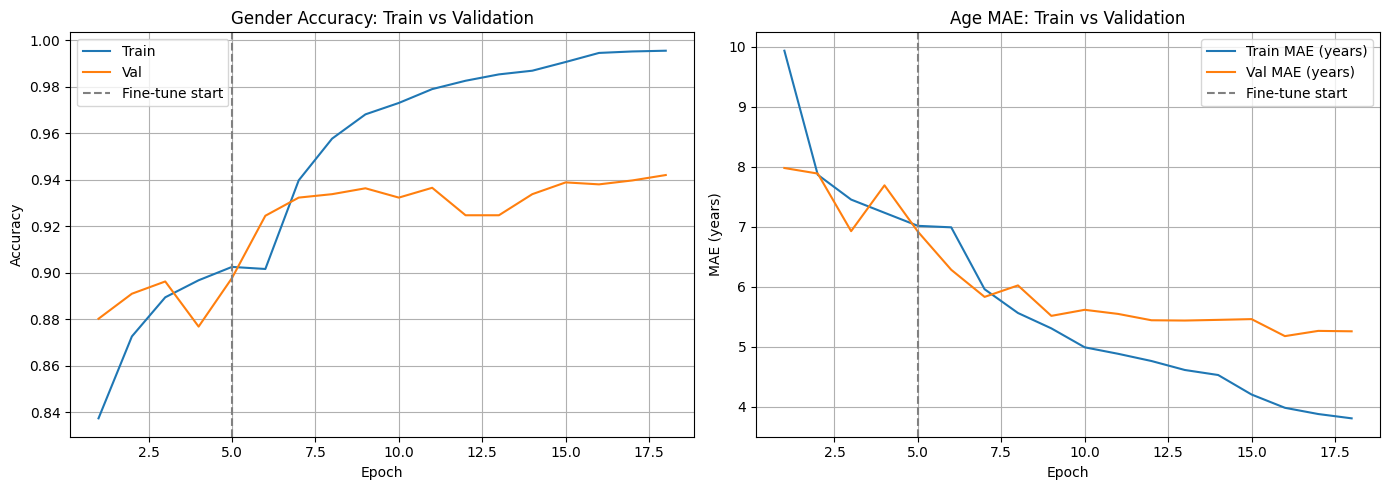

In [ ]:
# Merge Stage 1 + Stage 2 histories
all_history = {}
for key in history1.history:
    all_history[key] = history1.history[key] + history2.history[key]

stage1_len = len(history1.history['gender_accuracy'])
epochs = range(1, len(all_history['gender_accuracy']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, all_history['gender_accuracy'],     label='Train')
axes[0].plot(epochs, all_history['val_gender_accuracy'], label='Val')
axes[0].axvline(stage1_len, color='gray', linestyle='--', label='Fine-tune start')
axes[0].set_title('Gender Accuracy: Train vs Validation')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

train_mae_yrs = np.array(all_history['age_mae'])
val_mae_yrs   = np.array(all_history['val_age_mae'])
axes[1].plot(epochs, train_mae_yrs, label='Train MAE (years)')
axes[1].plot(epochs, val_mae_yrs,   label='Val MAE (years)')
axes[1].axvline(stage1_len, color='gray', linestyle='--', label='Fine-tune start')
axes[1].set_title('Age MAE: Train vs Validation')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE (years)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 8. Evaluation Metrics

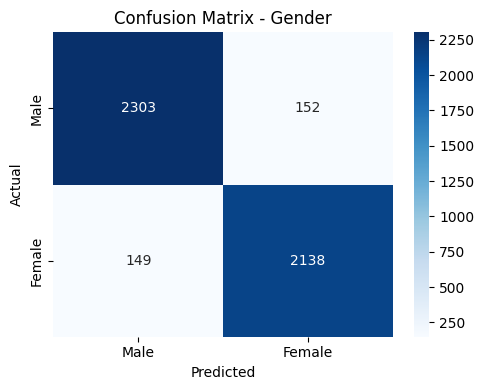

GENDER CLASSIFICATION METRICS
Accuracy  : 0.9365
Precision : 0.9336
Recall    : 0.9348
F1 Score  : 0.9342

AGE REGRESSION METRICS (years)
MAE  : 5.55 years
MSE  : 65.43
RMSE : 8.09 years
R2   : 0.8365


In [ ]:
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, mean_absolute_error,
    mean_squared_error, r2_score
)

# Collect predictions batch by batch — no large array in RAM
y_gender_true, y_age_true_norm = [], []
pred_gender_prob, pred_age_norm = [], []

for imgs, labels in val_ds:
    pg, pa = model.predict(imgs, verbose=0)
    pred_gender_prob.extend(pg.flatten())
    pred_age_norm.extend(pa.flatten())
    y_gender_true.extend(labels['gender'].numpy())
    y_age_true_norm.extend(labels['age'].numpy())

y_gender_true   = np.array(y_gender_true)
pred_gender_lbl = (np.array(pred_gender_prob) > 0.5).astype(int)
y_age_true_yrs  = np.array(y_age_true_norm)   # already in raw years
pred_age_yrs    = np.array(pred_age_norm)     # already in raw years

# Confusion matrix
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_gender_true, pred_gender_lbl)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Male', 'Female'],
            yticklabels=['Male', 'Female'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Gender')
plt.tight_layout()
plt.show()

print('=' * 35)
print('GENDER CLASSIFICATION METRICS')
print('=' * 35)
print(f'Accuracy  : {accuracy_score(y_gender_true, pred_gender_lbl):.4f}')
print(f'Precision : {precision_score(y_gender_true, pred_gender_lbl):.4f}')
print(f'Recall    : {recall_score(y_gender_true, pred_gender_lbl):.4f}')
print(f'F1 Score  : {f1_score(y_gender_true, pred_gender_lbl):.4f}')
print()
print('=' * 35)
print('AGE REGRESSION METRICS (years)')
print('=' * 35)
print(f'MAE  : {mean_absolute_error(y_age_true_yrs, pred_age_yrs):.2f} years')
print(f'MSE  : {mean_squared_error(y_age_true_yrs, pred_age_yrs):.2f}')
print(f'RMSE : {np.sqrt(mean_squared_error(y_age_true_yrs, pred_age_yrs)):.2f} years')
print(f'R2   : {r2_score(y_age_true_yrs, pred_age_yrs):.4f}')

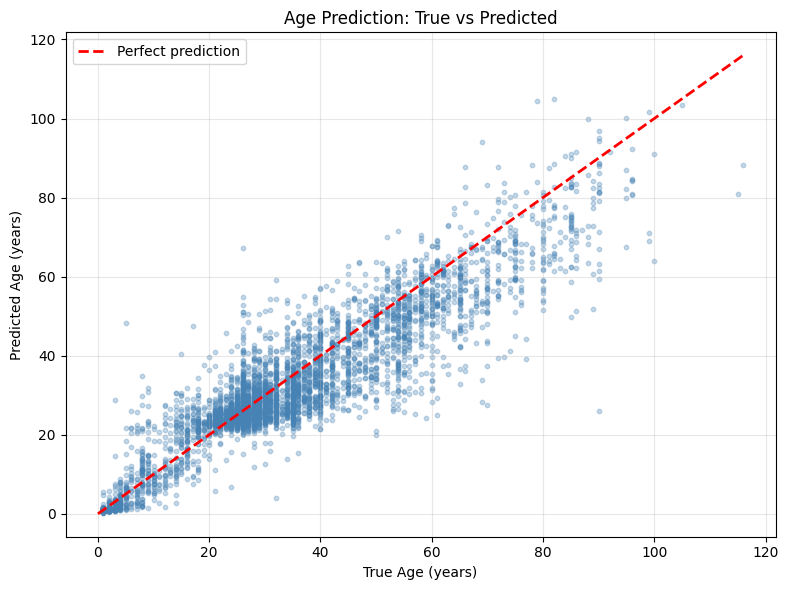

In [ ]:
# Age scatter: True vs Predicted
plt.figure(figsize=(8, 6))
plt.scatter(y_age_true_yrs, pred_age_yrs, alpha=0.3, s=10, color='steelblue')
plt.plot([0, 116], [0, 116], 'r--', linewidth=2, label='Perfect prediction')
plt.xlabel('True Age (years)')
plt.ylabel('Predicted Age (years)')
plt.title('Age Prediction: True vs Predicted')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Qualitative Predictions on Sample Images

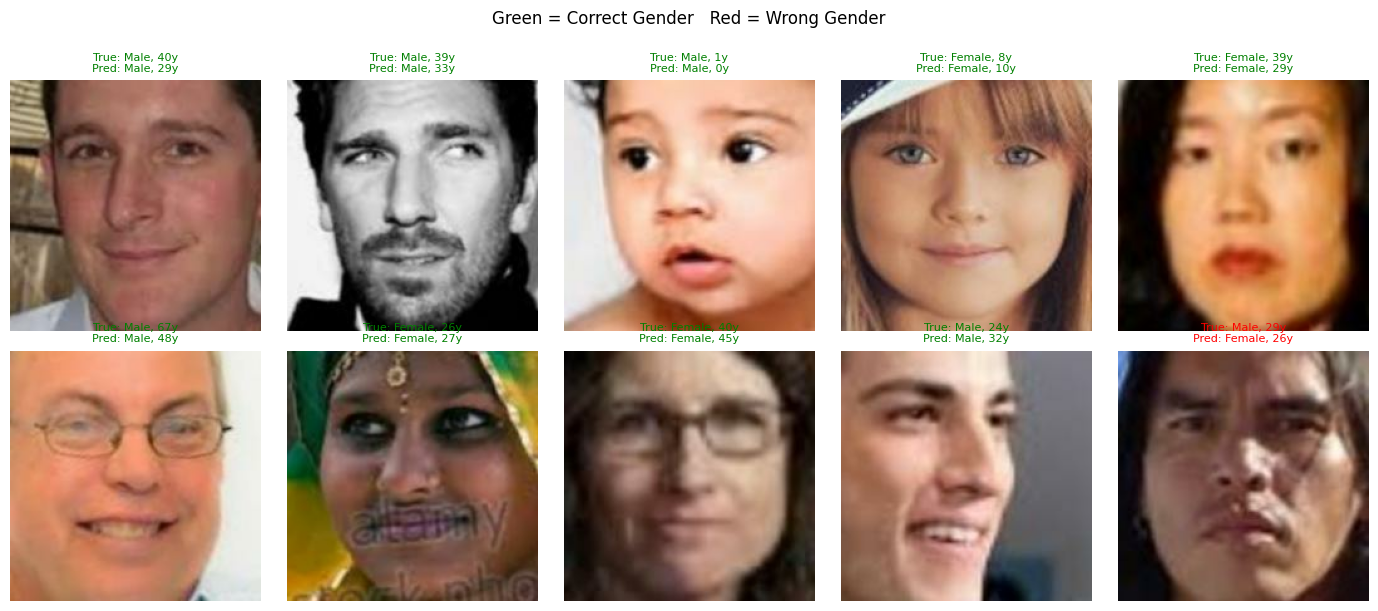

In [ ]:
sample_df = df_val.sample(10, random_state=7).reset_index(drop=True)

plt.figure(figsize=(14, 6))
for i, row in sample_df.iterrows():
    # Load and preprocess single image for display
    img_raw = tf.io.read_file(row['image'])
    img_dec = tf.image.decode_jpeg(img_raw, channels=3)
    img_res = tf.image.resize(img_dec, [IMG_SIZE, IMG_SIZE])
    inp     = preprocess_input(tf.cast(img_res, tf.float32))[tf.newaxis]

    pg, pa = model.predict(inp, verbose=0)
    pred_g = gender_dict[int(pg[0][0] > 0.5)]
    pred_a = int(pa[0][0])  # already in raw years
    true_g = gender_dict[row['gender']]
    true_a = row['age']

    color = 'green' if pred_g == true_g else 'red'

    plt.subplot(2, 5, i + 1)
    plt.imshow(tf.cast(img_dec, tf.uint8).numpy())
    plt.title(f'True: {true_g}, {true_a}y\nPred: {pred_g}, {pred_a}y', color=color, fontsize=8)
    plt.axis('off')

plt.suptitle('Green = Correct Gender   Red = Wrong Gender', y=1.01)
plt.tight_layout()
plt.show()